In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi




In [4]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

data_root = str(FIGURES / "figureS2") + "/"

mice=['cm125','cm126','cm128']



In [21]:
choice_body_part_dict = {0:'RW',1:'RM_M2',2:'RFP_M2',3:'LatM'}




In [40]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'
palatte_dict['RM_M2']='#bf8fc9'
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#C44B30'
palatte_dict['LFP_M2']=palatte_dict['RFP_M2']
palatte_dict['LM_M2']=palatte_dict['RM_M2']
palatte_dict['LatM']= palatte_dict['ALM']

In [42]:


palette_body=['#adcee9','#0c4666','#f4c784','#e97877']
palette_face=['#D15134','#7B4EA1','#2A7377','#BAB2AC','#2C5B78','#FFAE4E',]




In [8]:
behaviros_body_w_order = [
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_face_pc','norm_M_pupil_pc_norm']

all_bev_short_dict={'norm_M_whisk_vel_norm':'whisk','norm_M_mirrorLHP_vel_norm':'mLHP','norm_M_mirrorRHP_vel_norm':'mRHP',
                     'norm_M_mirrorLFP_vel_norm':'mLFP','norm_M_mirrorRFP_vel_norm':'mRFP','norm_M_LFP_vel_norm':'LFP',
                      'norm_M_RFP_vel_norm':'RFP','norm_M_rotf':'rotary','norm_M_body_pc':'body PC','norm_M_face_pc':'face PC',
                    'norm_M_pupil_pc_norm':'pupil PC'}

## load data

In [9]:
all_gathered_dict = {}
for mouse in mice:
    all_gathered_dict[mouse] = load_pickle(data_root+'STIM_'+mouse+'_final')


**concat data**

In [17]:
all_gathered_dict[mouse]['jrgeco2plot'].keys()

dict_keys(['RW', 'LM_M2', 'LFP_M2', 'LatM'])

In [19]:
all_gathered_dict[mouse]['norm_jrgeco_zscored_std']['RW'].shape

(200, 12)

In [43]:
T_PRE = 100     #same for all 3 mice
for i_behavior,behavior in enumerate(behaviros_body_w_order):
    exec("{}=[]".format(behavior))
    for mouse in mice:
        exec("{}.append(all_gathered_dict[mouse][behavior][T_PRE-70:T_PRE+70,:])".format(behavior))
        print(mouse,all_gathered_dict[mouse][behavior].shape[-1])
    exec("{} = np.concatenate({},1)".format(behavior,behavior))

for i_behavior,behavior in enumerate(behaviros_face_w_order):
    exec("{}=[]".format(behavior))
    for mouse in mice:
        exec("{}.append(all_gathered_dict[mouse][behavior][T_PRE-70:T_PRE+70,:])".format(behavior))
    exec("{} = np.concatenate({},1)".format(behavior,behavior))
    

norm_jrgeco_zscored_std={}
norm_jrgeco2plot={}
for i_bdp in range(4):
    bdp = choice_body_part_dict[i_bdp]
    bdp_correct = bdp.replace('RM_M2','LM_M2').replace('RFP_M2','LFP_M2')
    jrgeco_zscored_std_temp = [];jrgeco_temp = []
    for mouse in mice:
        if mouse == 'cm128':
            jrgeco_temp.append(all_gathered_dict[mouse]['jrgeco2plot'][bdp_correct][T_PRE-70:T_PRE+70,:])
            jrgeco_zscored_std_temp.append(all_gathered_dict[mouse]['norm_jrgeco_zscored_std'][bdp_correct][T_PRE-70:T_PRE+70,:])
        else:
            jrgeco_temp.append(all_gathered_dict[mouse]['jrgeco2plot'][bdp][T_PRE-70:T_PRE+70,:])
            jrgeco_zscored_std_temp.append(all_gathered_dict[mouse]['norm_jrgeco_zscored_std'][bdp][T_PRE-70:T_PRE+70,:])
    
    norm_jrgeco2plot[bdp] = np.concatenate(jrgeco_temp,1)
    norm_jrgeco_zscored_std[bdp] = np.concatenate(jrgeco_zscored_std_temp,1)

 

cm125 24
cm126 15
cm128 12


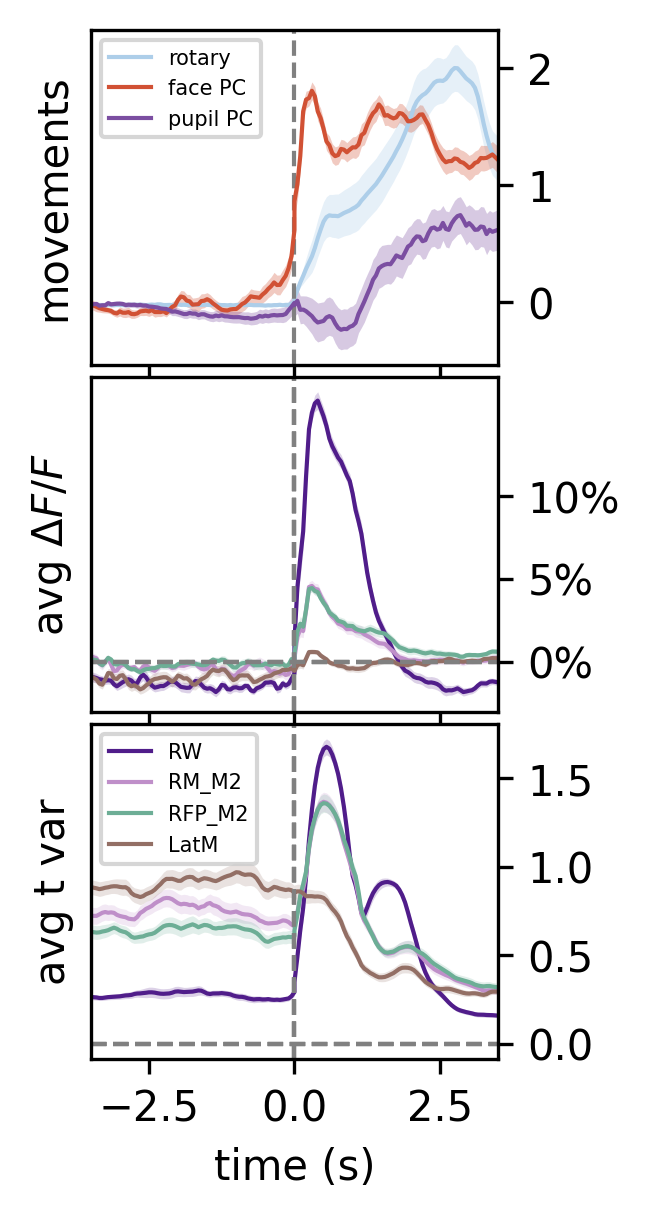

In [46]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5

# behavior (body and facial movements)
x_start = x_offset 
x_stop = x_start+6
y_start = y_offset 
y_stop = y_start+5
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop
    y_stop = y_start+5
    if i_ax < 2:
        exec("ax{}.set_xticklabels([])".format(i_ax)) 
    
# ax3 = fig.add_subplot(gs[y_start:y_start+1,x_start:x_stop])
# ax3.set_yticks([])

########################################
########################################

t_frame_trimmed = np.linspace(-70,70,140).astype('int')
t_ax_trimmed = np.divide(t_frame_trimmed,20)

# ampltitude
for i_bdp in range(4):
    bdp = choice_body_part_dict[i_bdp]

    data2plot = norm_jrgeco2plot[bdp]
    
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax1.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],label=bdp,linewidth=1)
    ax1.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.2,linewidth=0)
    ax1.axvline(0,linewidth=1,linestyle='dashed',color='gray')
    ax1.axhline(0,linewidth=1,linestyle='dashed',color='gray')
    ax1.set_yticks([0,0.05,0.1])
    vals = ax1.get_yticks()
    ax1.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
    ax1.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax2.set_yticklabels([])

    
for i_bdp in range(4):
    bdp = choice_body_part_dict[i_bdp]
    

    data2plot = norm_jrgeco_zscored_std[bdp]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax2.plot(t_ax_trimmed,avg,color=palatte_dict[bdp],label=bdp,linewidth=1)
    ax2.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palatte_dict[bdp],alpha=0.2,linewidth=0)
    ax2.axvline(0,linewidth=1,linestyle='dashed',color='gray')
    # ax1.set_yticks([-0.2,0,0.02])
    ax2.axhline(0,linewidth=1,linestyle='dashed',color='gray')
    ax2.set_xlim([t_ax_trimmed[0],t_ax_trimmed[-1]])
    # ax1.set_xticklabels([])


    
# NOW plot behavior
# body movements

behaviros_body_w_order = [
                     'norm_M_rotf']
behaviros_face_w_order = ['norm_M_face_pc','norm_M_pupil_pc_norm']

all_bev_short_dict={'norm_M_whisk_vel_norm':'whisk','norm_M_mirrorLHP_vel_norm':'mLHP','norm_M_mirrorRHP_vel_norm':'mRHP',
                     'norm_M_mirrorLFP_vel_norm':'mLFP','norm_M_mirrorRFP_vel_norm':'mRFP','norm_M_LFP_vel_norm':'LFP',
                      'norm_M_RFP_vel_norm':'RFP','norm_M_rotf':'rotary','norm_M_body_pc':'body PC','norm_M_face_pc':'face PC',
                    'norm_M_pupil_pc_norm':'pupil PC'}
for i_behavior,behavior in enumerate(behaviros_body_w_order):
    exec("beh2plot = {}".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_body[i_behavior],linewidth=1,label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palette_body[i_behavior],alpha=0.3,linewidth=0)
    ax0.set_xlim(np.divide([-70,70],20))
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


ax0.axvline(0,linewidth=1,linestyle='dashed',color='gray')
  



for i_behavior,behavior in enumerate(behaviros_face_w_order):
    exec("beh2plot = {}".format(behavior))
    avg = np.mean(beh2plot,axis=1)#+i_behavior*2.5
    sem = stats.sem(beh2plot,axis=1)
    ax0.plot(t_ax_trimmed,avg,color=palette_face[i_behavior],linewidth=1,label=all_bev_short_dict[behavior])
    ax0.fill_between(t_ax_trimmed, avg - sem,avg + sem,color=palette_face[i_behavior],alpha=0.3,linewidth=0)
    ax0.set_xlim(np.divide([-70,70],20))
    # ax2.text(t_ax[0]+0.3,i_behavior*2.5+0.35,all_bev_short_dict[behavior],color=behavior_colors[i_behavior],fontsize=10)


# for i_win,win in enumerate(['win1','win2','win3','win4']):
#     exec("win_here = {}[T_PRE-100:T_PRE+100]".format(win))
#     ax3.vlines(t_ax_trimmed[np.where(win_here==True)], 0, 0.5,linewidth=1,color=sns.color_palette("Set2")[i_win])
#     ax3.vlines(0, 8, 9,linewidth=10,color=sns.color_palette("Set2")[i_win],label=win_here)#for the legend
# ax3.set_ylim([0,0.5])
    
    
####
ax0.legend(fontsize=5)
ax2.legend(fontsize=5)
# ax2.legend(fontsize=5)
ax1.set_ylabel('avg $\Delta F/F$')
ax2.set_ylabel('avg t var')
ax0.set_ylabel('movements');  
ax2.set_xlabel('time (s)')

ax0.yaxis.tick_right()
ax1.yaxis.tick_right()
ax2.yaxis.tick_right()
###
plt.savefig('figS2-stim-TC.svg',format='svg',dpi=300)

## brain map

In [68]:
with h5py.File(figure_config_root+'mask_midline_'+'cm125'+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T

In [69]:
stim_map = np.mean(np.mean(all_gathered_dict['cm125']['norm_MM_jrgeco'][:,:,100:120,:],-1),-1)
stim_map = np.multiply(mask_midline,stim_map)

In [78]:
mouse = 'cm125'
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+'cm125')
choice_dict = {0:sensory_ind['RW'],1:[],2:[],3:418} #cm125
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
# plt.imshow(IDX_sorted)

dict_seed_ROI_xy_mice  = load_pickle(figure_config_root+'dict_seed_ROI_xy_mice')

list_choice_M2_l_n_r = ['RFP','RM','RW','RHP','LFP','LM','LW','LHP']
seed_ROI_xy = dict_seed_ROI_xy_mice[mouse]
node_coords_M2 = {}
for i_bdp in range(8):
    bdp = list_choice_M2_l_n_r[i_bdp]
    y_top_left = seed_ROI_xy[bdp]['y_top_left']
    y_botton_right = seed_ROI_xy[bdp]['y_botton_right']
    x_top_left =seed_ROI_xy[bdp]['x_top_left']
    x_botton_right=seed_ROI_xy[bdp]['x_botton_right']
    node_coords_M2[bdp] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
     


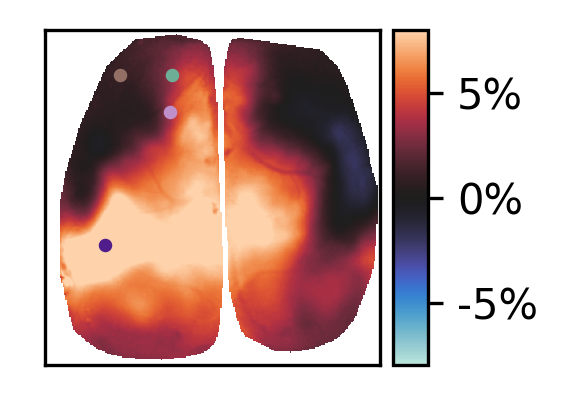

In [87]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5

x_start = x_offset 
x_stop = x_start+5
y_start = y_offset 
y_stop = y_start+5

ax0 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])
ax0.set_xticks([]);ax0.set_yticks([]);

ax990 = fig.add_subplot(gs[y_start:y_stop,x_stop:x_stop+1])


sbp0=ax0.imshow(stim_map,
          cmap='icefire',vmin=-0.08,vmax=0.08)


cb = fig.colorbar(sbp0, cax=ax990,fraction=0.5,orientation='vertical',format=FuncFormatter(fmt));
ax990.set_aspect(60);ax990.set_anchor('W')
        
        

i_ax=0
for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    ind = choice_dict[i_bdp]
    bdp = choice_body_part_dict[bdp_ind]
    if len(bdp.split('_'))==1:
        exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_ax))
    else:
        if bdp.split('_')[1] == 'M2':
            exec("ax{}.scatter(node_coords_M2[bdp.split('_')[0]][0], node_coords_M2[bdp.split('_')[0]][1], s=5, c=palatte_dict[bdp], zorder=2)".format(i_ax))
        else:
            exec("ax{}.scatter(node_coords[ind,1],node_coords[ind,0],s=5,color=palatte_dict[bdp])".format(i_ax))
    
    
plt.savefig('figS2-ROI map.svg',format='svg',dpi=300)